In [ ]:
d

#**1.** **Understand the assignment**
Task	What you need to do
Train LightGBM	Build a model to predict house prices.
RandomizedSearch / Optuna	Find better hyperparameter combinations.
Feature Importance	Identify which features contribute most to predictions.
SHAP	Understand how individual features influence predictions.

2. Install and import libraries

In [1]:
!pip install lightgbm shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler

In [4]:
from google.colab import drive
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Hamza - AI ML-Learning/Day_1/data.csv"

df = pd.read_csv(file_path)

print(df.head())
print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
                  date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  2014-05-02 00:00:00   313000.0       3.0       1.50         1340      7912   
1  2014-05-02 00:00:00  2384000.0       5.0       2.50         3650      9050   
2  2014-05-02 00:00:00   342000.0       3.0       2.00         1930     11947   
3  2014-05-02 00:00:00   420000.0       3.0       2.25         2000      8030   
4  2014-05-02 00:00:00   550000.0       4.0       2.50         1940     10500   

   floors  waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5           0     0          3        1340              0      1955   
1     2.0           0     4          5        3370            280      1921   
2     1.0           0     0          4        1930              0      1966   
3     1.0           0     0          4        1000           1000   

Prepare features and target

In [5]:
features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "yr_built",
    "yr_renovated"
]

X = df[features]
y = df["price"]

# Remove rows where target is missing
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

# Remove infinite or invalid target values
valid = np.isfinite(y) & (y > 0)
X = X.loc[valid]
y = y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

Train the LightGBM model

In [6]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("lgbm", LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=15,
        random_state=42,
        verbosity=-1
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Evaluate the model

In [7]:
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("LightGBM Results")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

LightGBM Results
MAE: 168294.55008904784
MSE: 67579532646.56338
RMSE: 259960.63672518457
R2 Score: 0.5457460833864297


In [ ]:
Hyperparameter tuning using RandomizedSearchCV

In [8]:
param_grid = {
    "lgbm__n_estimators": [100, 200, 300, 500],
    "lgbm__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "lgbm__max_depth": [-1, 3, 5, 7, 10],
    "lgbm__num_leaves": [7, 15, 20, 31, 50],
    "lgbm__min_child_samples": [10, 20, 30, 50],
    "lgbm__subsample": [0.7, 0.8, 0.9, 1.0],
    "lgbm__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "lgbm__reg_alpha": [0, 0.1, 1, 5],
    "lgbm__reg_lambda": [0, 0.1, 1, 5]
}

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=30,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best Parameters:")
print(search.best_params_)

best_model = search.best_estimator_

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best Parameters:
{'lgbm__subsample': 0.7, 'lgbm__reg_lambda': 5, 'lgbm__reg_alpha': 0.1, 'lgbm__num_leaves': 15, 'lgbm__n_estimators': 100, 'lgbm__min_child_samples': 50, 'lgbm__max_depth': -1, 'lgbm__learning_rate': 0.03, 'lgbm__colsample_bytree': 0.8}


Evaluate the tuned model:

In [9]:
tuned_predictions = best_model.predict(X_test)

print("Tuned LightGBM Results")
print("MAE:", mean_absolute_error(y_test, tuned_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, tuned_predictions)))
print("R2:", r2_score(y_test, tuned_predictions))

Tuned LightGBM Results
MAE: 165111.03661900858
RMSE: 268578.6831629293
R2: 0.5151285903363851


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Plot Feature Importance

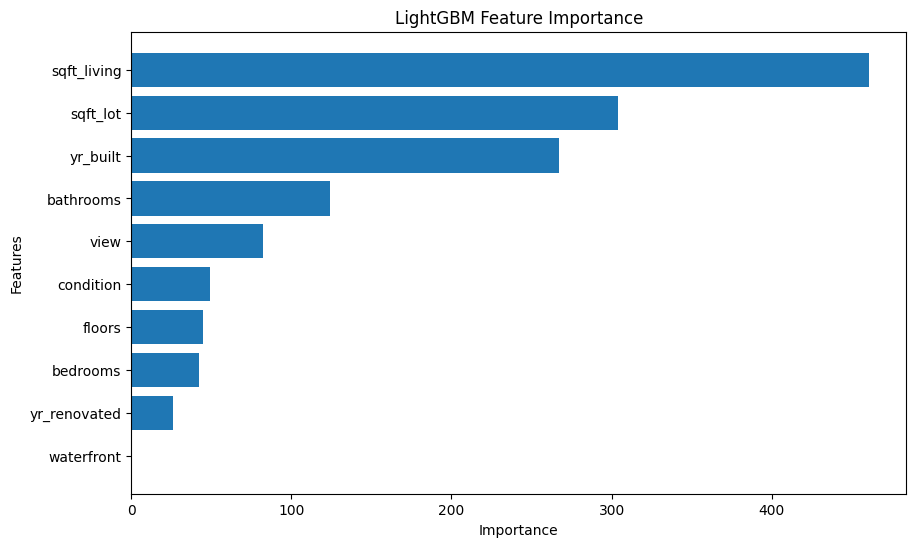

In [10]:
lgbm_model = best_model.named_steps["lgbm"]

importance = pd.DataFrame({
    "Feature": features,
    "Importance": lgbm_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("LightGBM Feature Importance")
plt.gca().invert_yaxis()
plt.show()

SHAP Analysis

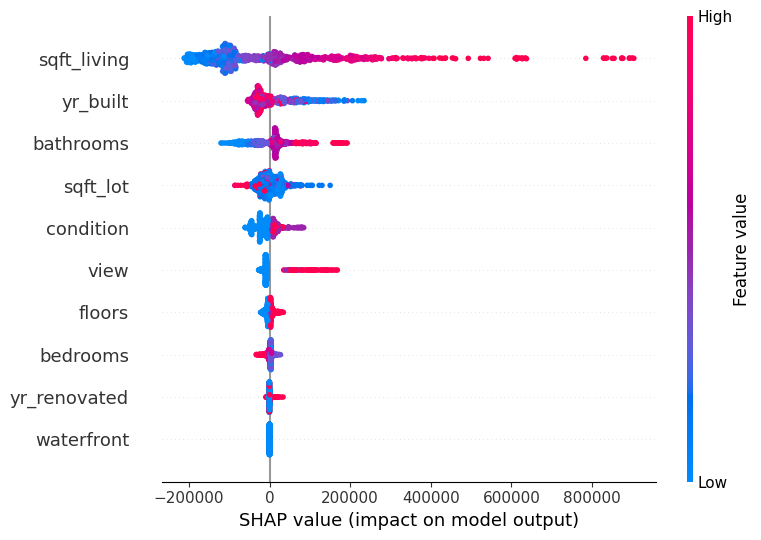

In [11]:
import shap

# Transform test data using the fitted imputer
X_test_imputed = best_model.named_steps["imputer"].transform(X_test)

X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=features,
    index=X_test.index
)

explainer = shap.TreeExplainer(lgbm_model)

shap_values = explainer(X_test_imputed)

shap.summary_plot(
    shap_values,
    X_test_imputed
)

You can also inspect one feature at a time:

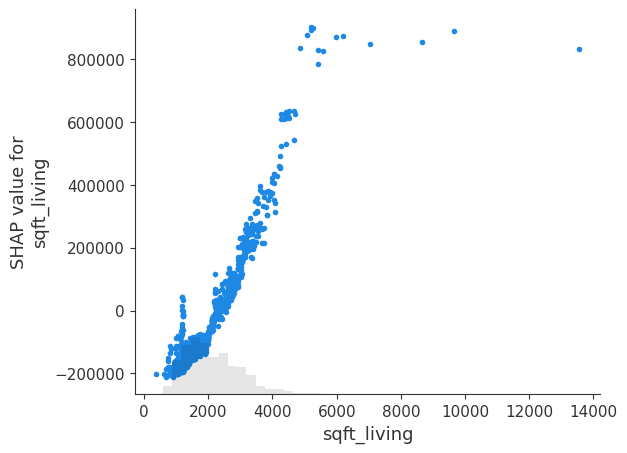

In [12]:
shap.plots.scatter(
    shap_values[:, "sqft_living"]
)